
# AI-Powered Shax (Shah) Game

**Team**: AI-Crackers  
**Members**:  
- Akram Seid Endris  
- Dawit Zemene Simie  
- Seid Mengistu Asnakew  
- Tsion Ketema Araya  

**Course**: Artificial Intelligence Fundamentals 2024/25  


## 1. Introduction

The goal of this project is to build a robust, GUI-based AI agent that plays Shax-a traditional Somali board game from the three-in-a-row family (like Nine Men’s Morris)-according to its authentic rules, with the ability to compete against both humans and other AI agents. Also known as Jare (meaning “cut”), Shax holds cultural significance in Somalia and was first implemented digitally by Jama Musse Jama in the late 1990s using C++. It shares its board layout with Nine Men’s Morris (three nested squares connected at the midpoints), but differs in two key ways: each player uses 12 pieces instead of 9, and piece removal occurs only after the first mill is formed during the opening phase, unlike Nine Men’s Morris where removals happen immediately after any mill. These features give Shax its distinct strategic depth and complexity.

## 2. Related Works

Despite the wide popularity of Shax across Africa. Especially in Somali communities. There is limited availability of digital implementations. We found only two significant examples online:

1. A **Human vs. Computer** version created by **Jama Musse Jama** in 1997 using C++ for DOS, later updated to run on Win32 in 2000.  
2. A **Human vs. Human** web-based version created by Reddit user **u/theDarkPrincexXR**, which can be accessed [here](https://wonderful-river-05ee9b710.5.azurestaticapps.net/).


## 3. Methodologies

In this project, we implemented several well-known adversarial search algorithms. Our development journey began with two classical approaches:

- **Minimax with Alpha-Beta Pruning**, and  
- **Monte Carlo Tree Search (MCTS)**.

As explained in the assessment section below, we observed that **Minimax’s performance was highly dependent on the structure of the search tree**. Meanwhile, the **random nature of MCTS** introduced variability in results and made it difficult to achieve consistent success.

Eventually, we enhanced our Minimax implementation with a **custom rule-based heuristic layer**. This addition significantly improved performance. The custom rules allowed the AI to make smarter decisions based on recognizable game patterns and strategic situations.

The heuristic enhancements provided the AI with capabilities such as:

- Detecting and forming potential **Jare (mill)** positions.  
- Detecting and **blocking opponent** mills.  
- Identifying and disrupting **back-and-forth mill traps** created by the opponent.  
- Searching for and executing **cyclical mill strategies** to repeatedly gain removals.

These additions made the AI more dynamic, strategic, and capable of handling real-game scenarios effectively.


## 4. Assessment

The performance of the computer players was assessed using the following key metrics:

- **Number of games won**, as Player 1 and as Player 2.  
- **Duration of each game**, measured in minutes and seconds, under different configurations.  

These metrics allow us to evaluate not just how often an AI wins, but also how efficiently it plays. 


## 5. Game Description

### 5.1 Board Representation

- The board has **24 positions**, indexed from 0 to 23.  
- There are **16 valid mill combinations**, each consisting of three aligned indices.  
- Each position has predefined **adjacent locations**, which determine legal movement during the game.


### 5.2 Rules & Phases

Shax is played on a 24-point board identical to that of Nine Men’s Morris. Each player has **12 pieces**, traditionally marked or colored. The objective is to form "mills" (three aligned pieces), which allow the removal of an opponent’s piece. The game consists of three distinct phases:

1. **Placement Phase (Setup)**  
   - Players alternate placing one piece per turn on any unoccupied point.  
   - Each player has 12 pieces, totaling 24 placements.  
   - If a player forms a mill (three in a straight line), it is recorded. The player who forms the **first mill** gains the right to remove an opponent's piece in the next phase.  
   - If **no mills** are formed, Player 2 (the second player) gains this right by default.

2. **Opening Phase (First Removal)**  
   - This phase occurs only once, after all pieces are placed.  
   - The player who formed the first mill removes **one** of the opponent’s pieces and the second player continue the removal.  
   - If no mills occurred, **Player 2** performs the first removal.

3. **Movement Phase**  
   - Players take turns sliding one of their pieces to an adjacent empty point.  
   - Forming a mill again allows for the removal of an opponent's piece.  
   - The game continues until a player has **fewer than three pieces** or **one of the player gave up**-both conditions result in a loss.

### 5.3 Win Conditions

- A player **loses** if they are reduced to fewer than **three pieces** (they can no longer form mills).  
- A player also **loses** if they have **no legal moves** on their turn.


By carefully modeling these rules and mechanics, the game environment supports both human intuition and strategic AI behavior. This project enables the application of advanced adversarial search techniques, such as Minimax and Monte Carlo Tree Search, within a culturally rich and tactically rewarding setting.



# Import required

In [12]:
import tkinter as tk
from frontend.ui import ShaxGame
from game_logger import GameLogger

**The Game Board**

The game board is similar to the well known Nine men's Morris game board with 24 empty positions at the start of the game and each player having 12 pieces each with green and yellow. The Board drawn using the Tkinter.

<img src="plots/shax_env't.png" width="400">

The Game is:


*   Fully observable :- Both players can see the entire board at all times.
*   Deterministic Enviroment :- The outcome of each action is predictable and consistent. 
*   Sequential movement :- Players take turns making moves one after the other.
*   Static enviroment :- The game state changes only when a player takes an action.
*   Discrete :- The game is discrete in both state space(24 fixed positions, finite piece combinations) and action space (a finite number of legal moves at each turn).
*   Multi-agent :- It is a two-player competitive game (adversarial).

In [9]:
def select_mode():
    print("Select game mode:")
    print("1: Minimax Without Rules vs MCTS")
    print("2: Minimax With Rules vs MCTS")
    print("3: Human vs Minimax With Rules")
    choice = input("Enter 1-3: ")
    return choice

In [10]:
def get_game_config(mode):
    if mode == "1":
        return {"1": "mwor", "2": "mcts"}, "MWOR vs MCTS"
    elif mode == "2":
        return {"1": "mcts", "2": "mwr"}, "MCTS vs MWR"
    elif mode == "3":
        return {"1": "human", "2": "mwr"}, "Human vs MWR"
    else:
        print("Invalid option.")
        exit()


In [11]:
def run_games(ai_config, logger, num_games=10):
    for i in range(num_games):
        print(f"\n=== Game {i + 1} / {num_games} started ===")
        root = tk.Tk()
        game = ShaxGame(root, ai_config=ai_config, logger=logger, game_number=i + 1)
        root.mainloop()
        root.destroy()
    game.logger.plot_game_analysis()

In [1]:
if __name__ == "__main__":
    mode = select_mode()
    ai_config, match_name = get_game_config(mode)
    logger = GameLogger(match_name)
    run_games(ai_config, logger)

## 6. Win/Loss Bar Chart
The bar chart below summarizes the number of wins and losses for each AI configuration.


In [17]:
import os
import json

def load_results_from_logs(folder='logs'):
    results = []
    if not os.path.exists(folder):
        print(f"[ERROR] Log folder '{folder}' not found.")
        return []

    for file in os.listdir(folder):
        if file.endswith('.json'):
            file_path = os.path.join(folder, file)
            try:
                with open(file_path, 'r') as f:
                    data = json.load(f)
                    results.extend(data)
            except Exception as e:
                print(f"[WARNING] Skipping {file} due to error: {e}")
    return results


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

def generate_summary(results):
    if not results:
        print("[WARNING] No results to summarize.")
        return pd.DataFrame()

    df = pd.DataFrame(results)
    df['duration_sec'] = pd.to_timedelta(df['duration']).dt.total_seconds()

    summary = {}
    configs = df['match_name'].unique()

    rows = 8
    cols = 4

    # Create the figure and subplots
    fig, axs = plt.subplots(rows, cols, figsize=(20, 20)) # Adjust figsize as needed
    axs = axs.flatten() # Flatten the 2D array of axes for easier iteration

    plot_index = 0
    for config in configs:
        sub_df = df[df['match_name'] == config]
        p1_wins = (sub_df['winner'] == 'Player 1').sum()
        p2_wins = (sub_df['winner'] == 'Player 2').sum()
        avg_duration = sub_df['duration_sec'].mean()

        summary[config] = {
            'P1 Wins': p1_wins,
            'P2 Wins': p2_wins,
            'Avg Duration (s)': round(avg_duration, 2),
            'Games': len(sub_df)
        }

        # Plot 1: Win Distribution
        if plot_index < len(axs): # Ensure we don't go out of bounds if more configs than available subplots
            axs[plot_index].bar(['P1', 'P2'], [p1_wins, p2_wins], color=['blue', 'orange'])
            axs[plot_index].set_title(f'{config} - Wins')
            axs[plot_index].set_ylabel('Wins')
            plot_index += 1

        # Plot 2: Game Duration Over Time
        if plot_index < len(axs):
            axs[plot_index].plot(range(1, len(sub_df)+1), sub_df['duration_sec'], marker='o', color='green')
            axs[plot_index].set_title(f'{config} - Duration')
            axs[plot_index].set_xlabel('Game #')
            axs[plot_index].set_ylabel('Duration (s)')
            plot_index += 1

    # Hide any unused subplots if the number of plots is less than rows * cols
    for i in range(plot_index, len(axs)):
        fig.delaxes(axs[i])

    plt.tight_layout()
    plt.show()

    # Return the summary DataFrame
    summary_df = pd.DataFrame.from_dict(summary, orient='index')
    print("\n--- Summary DataFrame ---")
    print(summary_df)


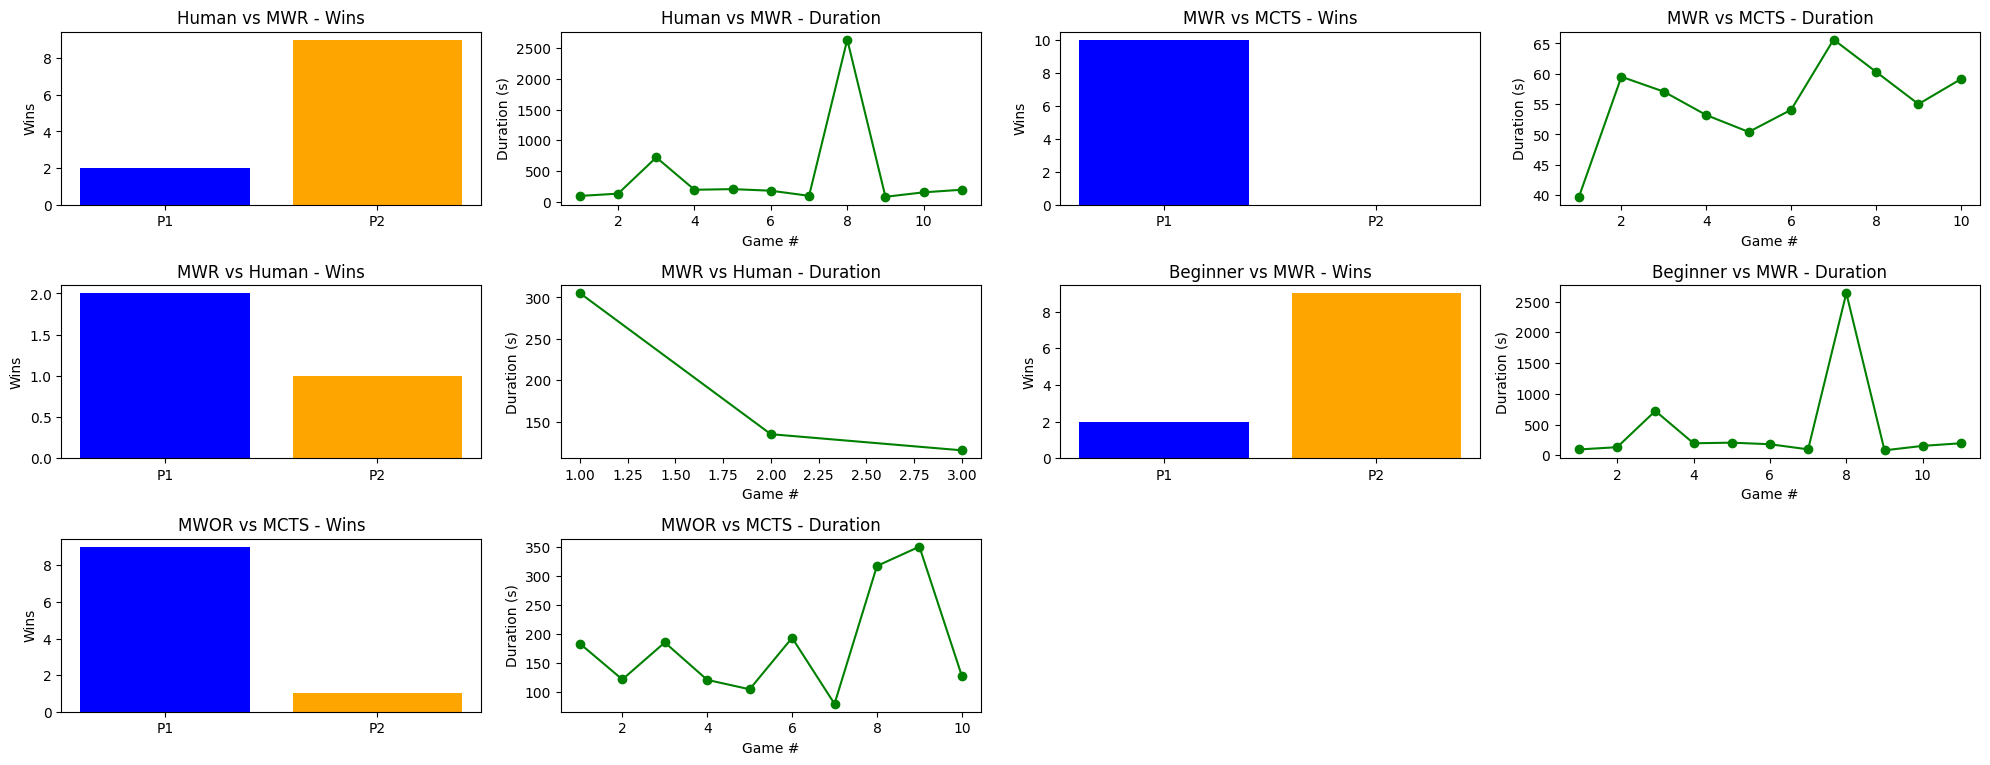


--- Summary DataFrame ---
                 P1 Wins  P2 Wins  Avg Duration (s)  Games
Human vs MWR           2        9            426.85     11
MWR vs MCTS           10        0             55.40     10
MWR vs Human           2        1            185.04      3
Beginner vs MWR        2        9            426.85     11
MWOR vs MCTS           9        1            178.63     10


In [28]:
results = load_results_from_logs("logs")
summary_df = generate_summary(results)
summary_df


## 7. Discussion

- **Minimax-with-Rules (MWR)** outperforms pure Minimax and MCTS:  
  - Heuristic layers effectively block and create mills.  
  - Reduced game length and increased win rate.  
- **MCTS** shows variability; good for exploration but inconsistent.  
- **Trade-off**: MWR is deterministic; MCTS offers diversity but slower.

## 8. Conclusion & Future Work

- **Conclusion**: Custom heuristics on top of α–β Minimax yield the best Shax AI.  
- **Future Work**:  
  1. **Parameter tuning** via self-play to optimize evaluation weights.  
  2. **Reinforcement learning** to adaptively learn heuristics.  
  3. **Web deployment** for broader user testing.
  4. **Enhanced UI** for better playing experience

## 9. Appendix


###  GitHub Metrics & Collaboration

- All source code, test logs, and assets were version-controlled using this github repository (https://github.com/Tsion-Ketema/AI-powered-shax-game.git).

###  Relationship with the Course

This project aligns directly with the learning objectives of the **Artificial Intelligence Fundamentals** course:

-  Applied **adversarial search algorithms** (Minimax with Alpha-Beta pruning)
-  Implemented **probabilistic reasoning** through Monte Carlo Tree Search (MCTS)
-  Designed a **fully observable**, **deterministic**, **discrete**, and **multi-agent environment**
-  Created and tested **heuristic evaluation functions** for complex board strategies
-  Practiced clean software design, code modularity, and logging-skills crucial in real-world AI systems

Through this hands-on implementation, we translated theoretical AI concepts into a working, competitive game-playing agent in a culturally significant environment.


## 10.  References

- Jama Musse Jama. *Shax AI for DOS*, 1997. Later ported to Windows in 2000.  
- u/theDarkPrincexXR. *Web-based Shax playground*. Available at: https://wonderful-river-05ee9b710.5.azurestaticapps.net/
- Russell, Stuart, and Peter Norvig. *Artificial Intelligence: A Modern Approach. 4th ed.* New York: Pearson, 2020.
